# Analisis Harga Rumah Jakarta

**Pertanyaan analisis**
1. Faktor apa yang paling berhubungan dengan harga rumah di Jakarta?
2. Wilayah mana yang paling mahal dan paling terjangkau per m²?
3. Di mana pembeli rumah pertama bisa mendapatkan rumah yang luas dengan harga di bawah median?

**Dataset:** [Jakarta House Price Dataset](https://www.kaggle.com/datasets/abiyyurasyiq/jakarta-house-price-dataset) (Kaggle), berisi sekitar 10.000 listing rumah di Jakarta dengan harga, wilayah, jumlah kamar, carport, luas tanah, dan luas bangunan.

**Catatan:** data ini kemungkinan besar berupa harga listing (penawaran), bukan harga transaksi.

**Alur:** Load data, Cleaning, Feature Engineering, EDA, Dashboard, Kesimpulan.

# 1. Data Understanding

In [86]:
!pip install kagglehub[pandas-datasets] -q

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Setting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load dataset langsung dari Kaggle
df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "abiyyurasyiq/jakarta-house-price-dataset",
    "jakarta_house.csv",
)

# Drop kolom 'index' (hanya nomor urut), abaikan kalau tidak ada
df = df.drop(columns=['index'], errors='ignore')

# Inspeksi awal
print("=== 5 Data Teratas ===")
print(df.head())
print("\n=== Informasi Dataset ===")
print(df.info())
print("\n=== Statistik Deskriptif ===")
print(df.describe())

Using Colab cache for faster access to the 'jakarta-house-price-dataset' dataset.
=== 5 Data Teratas ===
        price       district           city  bed_rooms  bath_rooms  carport  \
0  5900000000   Citra Garden  Jakarta Barat          2           4        2   
1  2700000000       Jelambar  Jakarta Barat          4           2        0   
2  2200000000       Jelambar  Jakarta Barat          3           3        0   
3  1900000000       Jelambar  Jakarta Barat          3           2        0   
4  2100000000  Tanjung Duren  Jakarta Barat          4           3        0   

   land_area  building_area  
0      250.0          350.0  
1      100.0          225.0  
2       60.0          140.0  
3       60.0          120.0  
4       56.0          108.0  

=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price        

# 2. Data Cleaning

## Missing Value

In [87]:
# Cek missing value
print("=== Missing Value per Kolom ===")
print(df.isnull().sum())

# Hapus baris yang kosong di land_area & building_area
df = df.dropna(subset=['land_area', 'building_area'])

print(f"\nJumlah data setelah drop missing: {len(df)} baris")

=== Missing Value per Kolom ===
price            0
district         0
city             0
bed_rooms        0
bath_rooms       0
carport          0
land_area        3
building_area    5
dtype: int64

Jumlah data setelah drop missing: 9992 baris


## Cek Outlier

In [88]:
# Hitung Q1, Q3, IQR untuk kolom price
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

print(f"Q1 (25%): Rp {Q1:,.0f}")
print(f"Q3 (75%): Rp {Q3:,.0f}")
print(f"IQR: Rp {IQR:,.0f}")
print(f"Batas Bawah (statistik): Rp {batas_bawah:,.0f}")
print(f"Batas Atas (statistik): Rp {batas_atas:,.0f}")

# Hitung jumlah outlier
outlier_bawah = df[df['price'] < batas_bawah]
outlier_atas = df[df['price'] > batas_atas]
print(f"\nJumlah outlier bawah: {len(outlier_bawah)} baris")
print(f"Jumlah outlier atas: {len(outlier_atas)} baris")
print(f"Total outlier: {len(outlier_bawah) + len(outlier_atas)} baris")

Q1 (25%): Rp 2,500,000,000
Q3 (75%): Rp 9,800,000,000
IQR: Rp 7,300,000,000
Batas Bawah (statistik): Rp -8,450,000,000
Batas Atas (statistik): Rp 20,750,000,000

Jumlah outlier bawah: 0 baris
Jumlah outlier atas: 1105 baris
Total outlier: 1105 baris


## Visualisasi Outlier

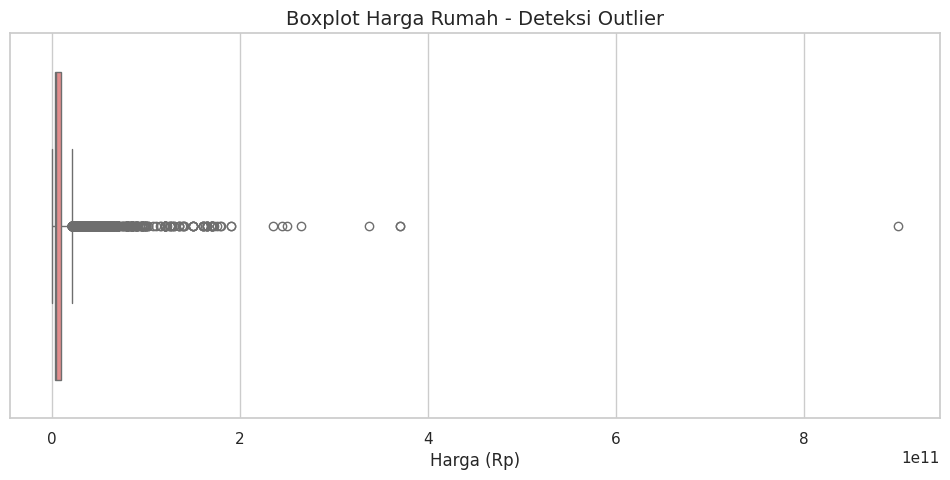

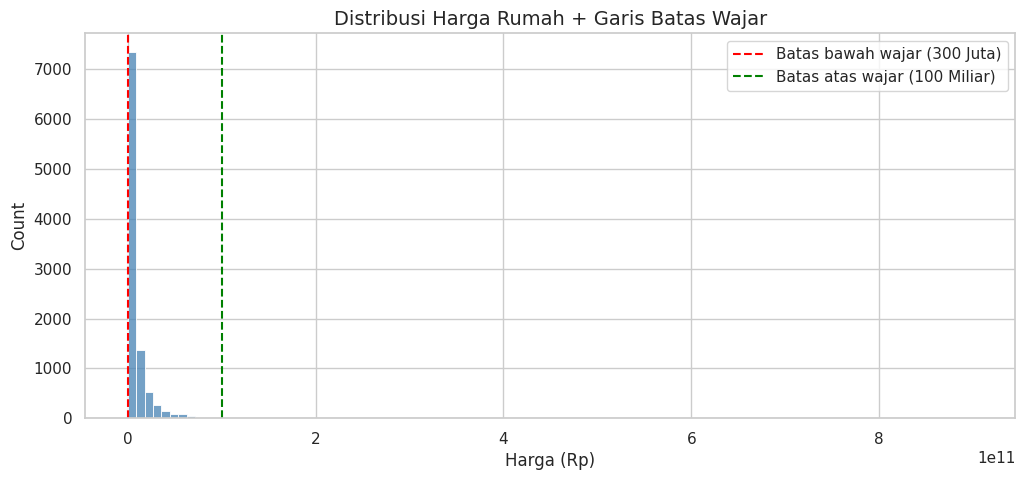

In [89]:
# Boxplot
plt.figure(figsize=(12, 5))
sns.boxplot(x=df['price'], color='lightcoral')
plt.title('Boxplot Harga Rumah - Deteksi Outlier', fontsize=14)
plt.xlabel('Harga (Rp)')
plt.show()

# Histogram + garis batas wajar
plt.figure(figsize=(12, 5))
sns.histplot(df['price'], bins=100, color='steelblue')
plt.axvline(300_000_000, color='red', linestyle='--', label='Batas bawah wajar (300 Juta)')
plt.axvline(100_000_000_000, color='green', linestyle='--', label='Batas atas wajar (100 Miliar)')
plt.title('Distribusi Harga Rumah + Garis Batas Wajar', fontsize=14)
plt.xlabel('Harga (Rp)')
plt.legend()
plt.show()

## Investigasi Outlier

In [90]:
# Lihat 10 rumah termurah
print("=== 10 Rumah Termurah ===")
print(df.nsmallest(10, 'price')[['district', 'city', 'bed_rooms', 'bath_rooms', 'land_area', 'building_area', 'price']])

# Lihat 10 rumah termahal
print("\n=== 10 Rumah Termahal ===")
print(df.nlargest(10, 'price')[['district', 'city', 'bed_rooms', 'bath_rooms', 'land_area', 'building_area', 'price']])

=== 10 Rumah Termurah ===
                  district             city  bed_rooms  bath_rooms  land_area  \
3744       Metland Menteng    Jakarta Timur          2           2       96.0   
3295           Kota Wisata    Jakarta Timur          5           4      160.0   
3291                Sunter    Jakarta Utara          3           2       50.0   
3289           Golf Island    Jakarta Utara          3           3       90.0   
3290               Cibubur    Jakarta Timur          4           2      395.0   
3298         Pondok Kelapa    Jakarta Timur          5           3      595.0   
3294                Tomang    Jakarta Barat          4           2      306.0   
3293                Kemang  Jakarta Selatan          4           4      379.0   
1013  Pantai Indah Kapuk 2    Jakarta Utara          4           5       45.0   
1012  Pantai Indah Kapuk 2    Jakarta Utara          4           4       90.0   

      building_area     price  
3744          100.0   1850000  
3295          200.

Rumah 1.85 juta, 2.2 juta, 2.3 juta, dst — semua di bawah 300 juta dan spek-nya tidak masuk akal (luas tanah 96-595 m², 4-5 kamar tidur). Ini error input.

Rumah 900 miliar di Pondok Indah dengan luas tanah 10.847 m² — ini mungkin valid (tanah raksasa).

## Filtering

In [91]:
n_awal = len(df)
print(f"Data awal: {n_awal} baris")

# 1. Buang outlier bawah (error input) - harga < 300 juta
df = df[df['price'] >= 300_000_000].copy()

# 2. Buang outlier atas yang tidak wajar - harga > 100 miliar
df = df[df['price'] <= 100_000_000_000].copy()

# 3. Filter land_area minimal wajar (>= 20 m²) - krusial untuk price_per_m2
df = df[df['land_area'] >= 20].copy()

# 4. Filter building_area minimal wajar (>= 20 m²)
df = df[df['building_area'] >= 20].copy()

# 5. Buang baris dengan bed_rooms & bath_rooms = 0 (kemungkinan data error)
df = df[(df['bed_rooms'] > 0) & (df['bath_rooms'] > 0)].copy()

print(f"Data setelah cleaning: {len(df)} baris")
print(f"Data yang dibuang: {n_awal - len(df)} baris")

# Cek ulang statistik
print("\n=== Statistik Setelah Cleaning ===")
print(df[['price', 'land_area', 'building_area', 'bed_rooms', 'bath_rooms']].describe())

Data awal: 9992 baris
Data setelah cleaning: 9605 baris
Data yang dibuang: 387 baris

=== Statistik Setelah Cleaning ===
              price     land_area  building_area    bed_rooms   bath_rooms
count  9.605000e+03   9605.000000    9605.000000  9605.000000  9605.000000
mean   8.840507e+09    277.603540     309.950442     4.323581     3.578449
std    1.224157e+10    328.790583     280.062923     3.108317     2.835012
min    3.000000e+08     20.000000      25.000000     1.000000     1.000000
25%    2.500000e+09    100.000000     140.000000     3.000000     2.000000
50%    4.400000e+09    172.000000     226.000000     4.000000     3.000000
75%    9.500000e+09    325.000000     400.000000     5.000000     4.000000
max    1.000000e+11  10350.000000    4878.000000    63.000000    63.000000


# 3. Feature Engineering

In [92]:
# 1. Harga per meter persegi
df['price_per_m2'] = df['price'] / df['land_area']

# 2. Kategori harga berdasarkan kuartil (bukan asumsi)
q1 = df['price'].quantile(0.25)
q2 = df['price'].quantile(0.50)
q3 = df['price'].quantile(0.75)
q4 = df['price'].quantile(0.90)

label_budget = f'Budget (< Rp{q1/1e9:.1f}B)'
label_mid    = f'Mid-Range (Rp{q1/1e9:.1f}-{q3/1e9:.1f}B)'
label_prem   = f'Premium (Rp{q3/1e9:.1f}-{q4/1e9:.1f}B)'
label_lux    = f'Luxury (> Rp{q4/1e9:.1f}B)'

def kategori_harga(price):
    if price < q1:
        return label_budget
    elif price < q3:
        return label_mid
    elif price < q4:
        return label_prem
    else:
        return label_lux

df['price_category'] = df['price'].apply(kategori_harga)

# Urutkan kategori supaya grafik tampil dari murah ke mahal
urutan = [label_budget, label_mid, label_prem, label_lux]
df['price_category'] = pd.Categorical(df['price_category'], categories=urutan, ordered=True)

# 3. Total kamar
df['total_rooms'] = df['bed_rooms'] + df['bath_rooms']

# 4. Rasio bangunan terhadap tanah (efisiensi lahan)
df['building_ratio'] = df['building_area'] / df['land_area']

# 5. Kategori carport
df['carport_cat'] = df['carport'].apply(lambda x: '0' if x == 0 else '1' if x == 1 else '2' if x == 2 else '3+')

# Cek hasil
print(df[['district', 'price', 'price_per_m2', 'price_category', 'total_rooms', 'building_ratio']].head(10))
print("\n=== Kategori Harga ===")
print(df['price_category'].value_counts())

         district        price  price_per_m2          price_category  \
0    Citra Garden   5900000000  2.360000e+07  Mid-Range (Rp2.5-9.5B)   
1        Jelambar   2700000000  2.700000e+07  Mid-Range (Rp2.5-9.5B)   
2        Jelambar   2200000000  3.666667e+07       Budget (< Rp2.5B)   
3        Jelambar   1900000000  3.166667e+07       Budget (< Rp2.5B)   
4   Tanjung Duren   2100000000  3.750000e+07       Budget (< Rp2.5B)   
5   Tanjung Duren   2650000000  3.955224e+07  Mid-Range (Rp2.5-9.5B)   
7           Tebet   7000000000  1.620370e+07  Mid-Range (Rp2.5-9.5B)   
8          Kemang  11000000000  2.083333e+07   Premium (Rp9.5-21.0B)   
9       Pulo Asem   3670000000  2.584507e+07  Mid-Range (Rp2.5-9.5B)   
10  Permata Buana   4600000000  3.194444e+07  Mid-Range (Rp2.5-9.5B)   

    total_rooms  building_ratio  
0             6        1.400000  
1             6        2.250000  
2             6        2.333333  
3             5        2.000000  
4             7        1.928571  
5  

# 4. Exploratory Data Analysis (EDA)

## Distrik Termahal per m²

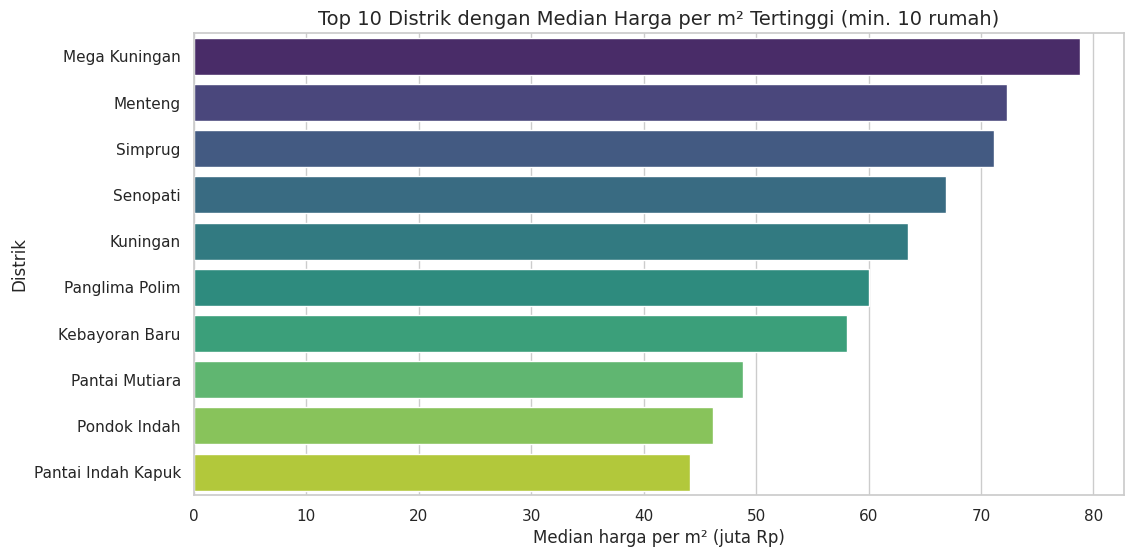

district
Mega Kuningan         78787879.0
Menteng               72289157.0
Simprug               71136364.0
Senopati              66863286.0
Kuningan              63492063.0
Panglima Polim        60081212.0
Kebayoran Baru        58096650.0
Pantai Mutiara        48800593.0
Pondok Indah          46188902.0
Pantai Indah Kapuk    44117647.0
Name: price_per_m2, dtype: float64

=== Perbandingan ===
Termahal: Mega Kuningan - Rp 78,787,879/m²
Termurah: Legenda Wisata - Rp 10,670,732/m²
Rasio: 7.4x


In [93]:
# Hanya distrik dengan minimal 10 rumah, pakai median agar tidak terpengaruh outlier
jumlah = df['district'].value_counts()
valid = jumlah[jumlah >= 10].index

stat = (df[df['district'].isin(valid)]
        .groupby('district')['price_per_m2'].median()
        .sort_values(ascending=False))

top_district_m2 = stat.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_district_m2.values / 1e6, y=top_district_m2.index,
            hue=top_district_m2.index, palette='viridis', legend=False)
plt.title('Top 10 Distrik dengan Median Harga per m² Tertinggi (min. 10 rumah)', fontsize=14)
plt.xlabel('Median harga per m² (juta Rp)')
plt.ylabel('Distrik')
plt.show()

print(top_district_m2.round(0))

print("\n=== Perbandingan ===")
print(f"Termahal: {stat.index[0]} - Rp {stat.iloc[0]:,.0f}/m²")
print(f"Termurah: {stat.index[-1]} - Rp {stat.iloc[-1]:,.0f}/m²")
print(f"Rasio: {stat.iloc[0] / stat.iloc[-1]:.1f}x")

## Pengaruh Kamar Tidur

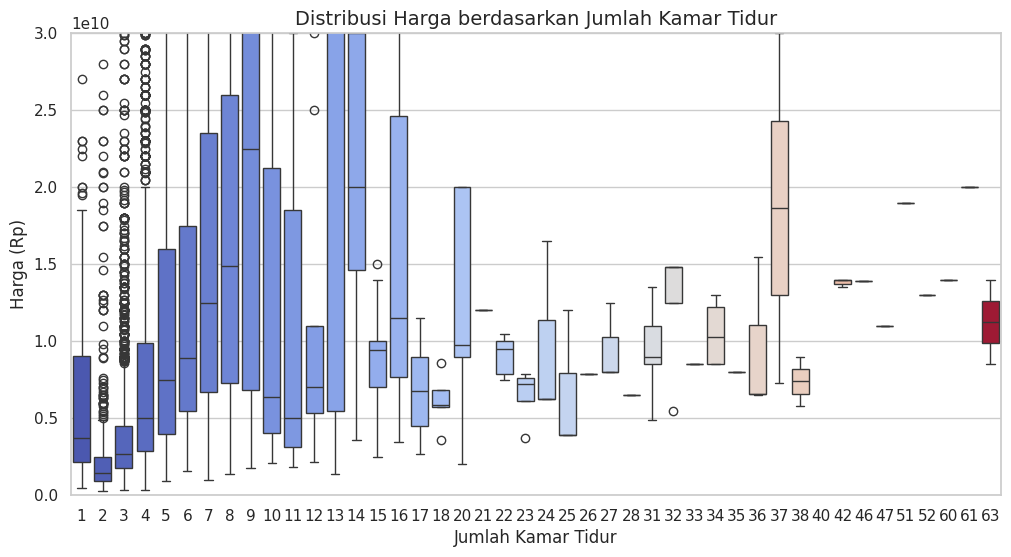

                   mean        median  count
bed_rooms                                   
1          7.808629e+09  3.745000e+09    124
2          2.814728e+09  1.450000e+09    739
3          4.424812e+09  2.650000e+09   2816
4          9.092857e+09  5.000000e+09   2976
5          1.234426e+10  7.500000e+09   1658
6          1.457681e+10  8.900000e+09    592
7          1.781606e+10  1.250000e+10    277
8          2.166526e+10  1.490000e+10    133
9          2.769216e+10  2.250000e+10     74
10         1.891389e+10  6.350000e+09     54
11         1.293684e+10  5.000000e+09     19
12         1.206667e+10  7.000000e+09     15
13         3.187267e+10  3.900000e+10     15
14         2.351250e+10  2.000000e+10      8
15         8.810000e+09  9.400000e+09     10
16         2.241929e+10  1.150000e+10     14
17         7.040000e+09  6.750000e+09      9
18         6.120000e+09  5.850000e+09      5
20         1.775000e+10  9.750000e+09      5
21         1.200000e+10  1.200000e+10      1
22        

In [94]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='bed_rooms', y='price', hue='bed_rooms', palette='coolwarm', legend=False)
plt.title('Distribusi Harga berdasarkan Jumlah Kamar Tidur', fontsize=14)
plt.xlabel('Jumlah Kamar Tidur')
plt.ylabel('Harga (Rp)')
plt.xticks(rotation=0)
plt.ylim(0, 30_000_000_000)  # Batasi untuk fokus visual
plt.show()

# Statistik pendukung
print(df.groupby('bed_rooms')['price'].agg(['mean', 'median', 'count']).round(0))

**Insight:** Median harga naik seiring jumlah kamar tidur, dari sekitar Rp1,45 miliar (2 kamar) hingga sekitar Rp22,5 miliar (9 kamar). Rumah 1 kamar tidur justru punya median lebih tinggi (Rp3,7 miliar) daripada rumah 2 kamar, dengan sampel kecil (124 rumah), sehingga kemungkinan berasal dari tipe properti yang berbeda. Rumah dengan kamar sangat banyak juga berjumlah sedikit, jadi polanya di sana kurang dapat diandalkan.

## Segmen Pasar per Kota

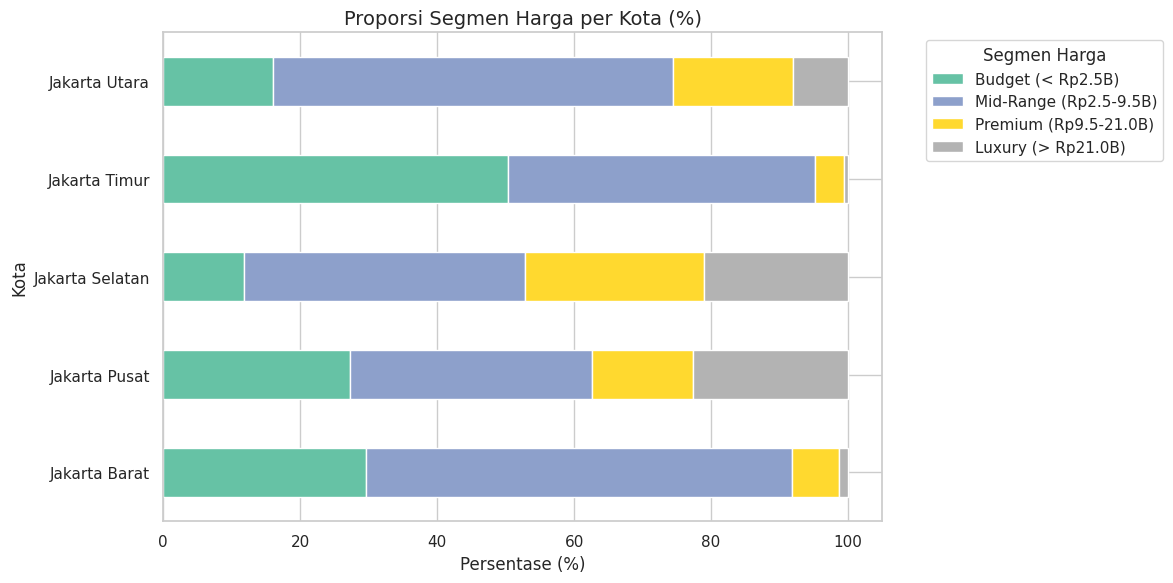

price_category   Budget (< Rp2.5B)  Mid-Range (Rp2.5-9.5B)  \
city                                                         
Jakarta Barat                 29.6                    62.2   
Jakarta Pusat                 27.3                    35.3   
Jakarta Selatan               11.7                    41.1   
Jakarta Timur                 50.3                    44.8   
Jakarta Utara                 16.1                    58.4   

price_category   Premium (Rp9.5-21.0B)  Luxury (> Rp21.0B)  
city                                                        
Jakarta Barat                      6.9                 1.3  
Jakarta Pusat                     14.8                22.6  
Jakarta Selatan                   26.0                21.1  
Jakarta Timur                      4.2                 0.7  
Jakarta Utara                     17.6                 8.0  


In [95]:
# Crosstab antara city dan price_category
pivot = pd.crosstab(df['city'], df['price_category'], normalize='index') * 100

pivot.plot(kind='barh', stacked=True, figsize=(12, 6), colormap='Set2')
plt.title('Proporsi Segmen Harga per Kota (%)', fontsize=14)
plt.xlabel('Persentase (%)')
plt.ylabel('Kota')
plt.legend(title='Segmen Harga', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

# Tabel pendukung
print(pd.crosstab(df['city'], df['price_category'], normalize='index').round(3) * 100)

Insight: Jakarta Timur didominasi segmen budget (sekitar 50% rumah), sedangkan Jakarta Pusat (22,6%) dan Jakarta Selatan (21,1%) punya porsi luxury terbesar. Segmen premium paling banyak ada di Jakarta Selatan (26%), dan Jakarta Barat didominasi segmen mid-range (sekitar 62%).

## Korelasi Variabel

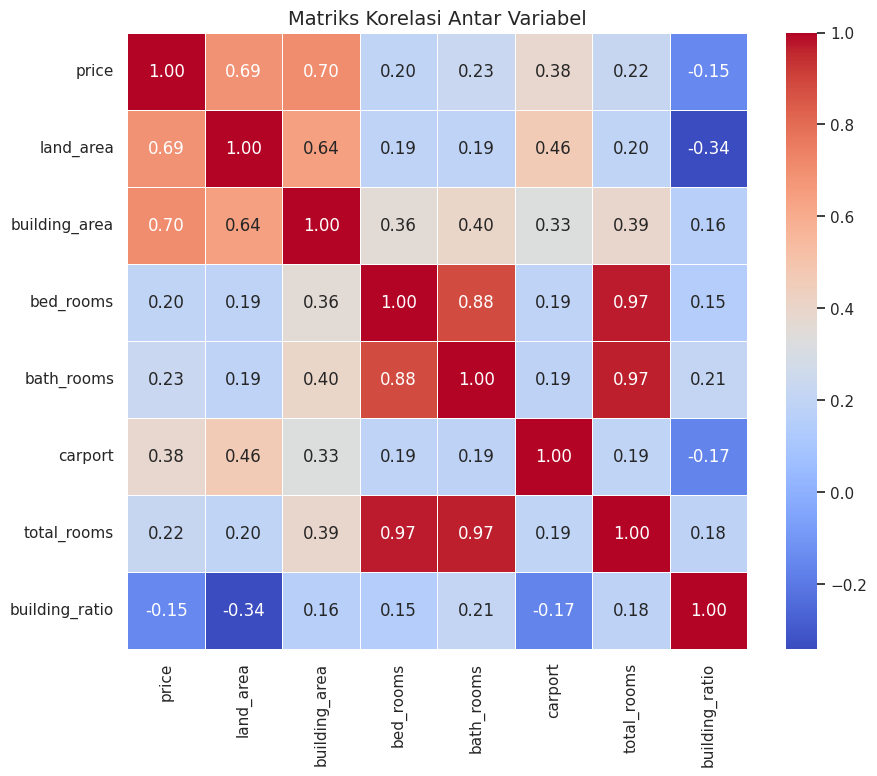


Korelasi dengan Harga:
price             1.000000
building_area     0.704631
land_area         0.687078
carport           0.382151
bath_rooms        0.230473
total_rooms       0.219955
bed_rooms         0.198034
building_ratio   -0.147908
Name: price, dtype: float64


In [96]:
# Hitung korelasi - masukkan fitur baru
korelasi = df[['price', 'land_area', 'building_area', 'bed_rooms',
               'bath_rooms', 'carport', 'total_rooms', 'building_ratio']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(korelasi, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi Antar Variabel', fontsize=14)
plt.show()

# Fokus ke korelasi dengan price
print("\nKorelasi dengan Harga:")
print(korelasi['price'].sort_values(ascending=False))

**Insight:** Luas bangunan (r ≈ 0,70) dan luas tanah (r ≈ 0,69) adalah variabel yang paling berkorelasi dengan harga. Jumlah carport berada di tingkat menengah (r ≈ 0,38), sementara jumlah kamar tidur dan kamar mandi hanya berkorelasi lemah (r ≈ 0,20 dan 0,23). Artinya, ukuran properti lebih menentukan harga daripada jumlah kamar. Catatan: korelasi menunjukkan hubungan, bukan sebab-akibat.

## Pengaruh Carport

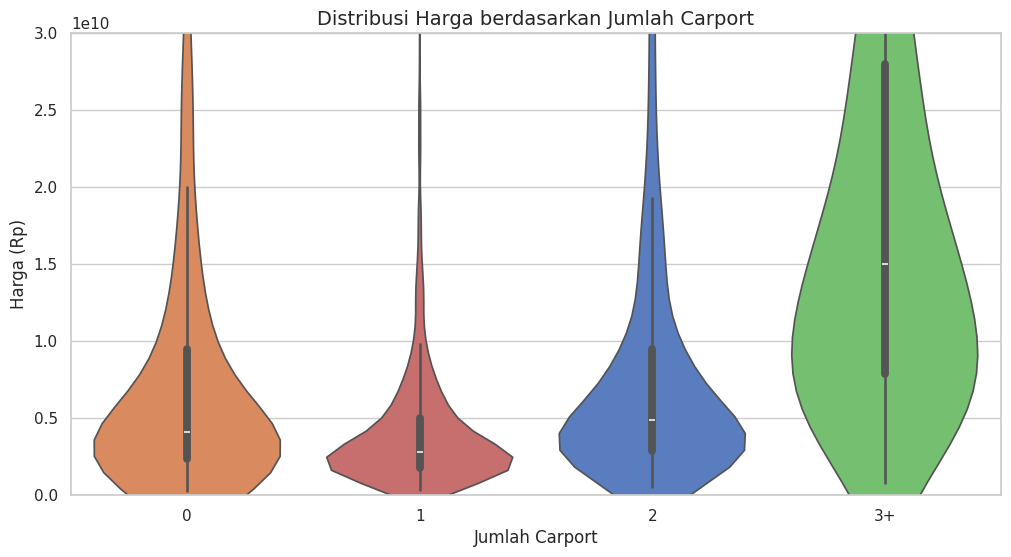

                     mean        median  count
carport_cat                                   
0            8.616251e+09  4.100000e+09   2115
1            4.335222e+09  2.800000e+09   3074
2            8.569038e+09  4.900000e+09   3195
3+           2.128186e+10  1.500000e+10   1221


In [97]:
plt.figure(figsize=(12, 6))
sns.violinplot(data=df, x='carport_cat', y='price', hue='carport_cat',
               palette='muted', order=['0', '1', '2', '3+'], legend=False)
plt.title('Distribusi Harga berdasarkan Jumlah Carport', fontsize=14)
plt.xlabel('Jumlah Carport')
plt.ylabel('Harga (Rp)')
plt.ylim(0, 30_000_000_000)
plt.show()

# Statistik pendukung
print(df.groupby('carport_cat')['price'].agg(['mean', 'median', 'count']).round(0))

**Insight:** Harga median naik tajam pada rumah dengan 3 carport atau lebih (sekitar Rp15 miliar). Namun rumah tanpa carport (median sekitar Rp4,1 miliar) justru lebih mahal daripada rumah dengan 1 carport (sekitar Rp2,8 miliar). Pola ini tidak berarti carport menurunkan harga. Kemungkinan rumah tanpa carport berasal dari kawasan atau tipe properti berbeda, sehingga perlu analisis lebih lanjut.

## Value for Money (Distrik Termurah)

In [98]:
# Filter distrik dengan minimal 10 rumah
district_count = df['district'].value_counts()
valid_districts = district_count[district_count >= 10].index

district_stats = (df[df['district'].isin(valid_districts)]
                  .groupby('district')
                  .agg(price_per_m2=('price_per_m2', 'median'),
                       total_rooms=('total_rooms', 'median'),
                       price=('price', 'median'),
                       land_area=('land_area', 'median'),
                       jumlah_rumah=('district', 'count'))
                  .round(0))

print("=== Distrik dengan Median Harga per m² Termurah (Value for Money) ===")
print(district_stats.sort_values('price_per_m2').head(10))

=== Distrik dengan Median Harga per m² Termurah (Value for Money) ===
                    price_per_m2  total_rooms         price  land_area  \
district                                                                 
Legenda Wisata        10670732.0          6.0  2.000000e+09      160.0   
Pulogebang            11750000.0          7.0  1.925000e+09      180.0   
Klender               12119963.0          4.0  1.090000e+09       79.0   
Cibubur               13333333.0          5.0  1.525000e+09      106.0   
Lenteng Agung         13514228.0          8.0  2.625000e+09      150.0   
Cipayung              14586214.0          5.0  1.000000e+09       66.0   
Citra Grand           15000000.0          7.0  2.600000e+09      136.0   
Kota Wisata           15079365.0          6.0  2.200000e+09      144.0   
Duri Kosambi          15102371.0          6.0  1.900000e+09      120.0   
Sektor 1 - Bintaro    15115152.0         10.0  8.700000e+09      591.0   

                    jumlah_rumah  
distri

**Insight:** Berdasarkan median harga per m², distrik termurah (minimal 10 rumah) adalah Legenda Wisata (sekitar Rp10,7 juta/m²), Pulogebang (Rp11,8 juta), Klender (Rp12,1 juta), dan Cibubur (Rp13,3 juta). Sebagian besar berada di kawasan timur Jakarta, sedangkan Lenteng Agung (Rp13,5 juta) ada di selatan. Cibubur punya sampel paling besar (146 rumah), sehingga hasilnya paling dapat diandalkan, sementara Lenteng Agung hanya 10 rumah dan perlu dibaca hati-hati.

## Sweet Spot untuk First-Time Buyer

In [99]:
# Rumah dengan harga < median, tapi total_rooms > median
median_price = df['price'].median()
median_rooms = df['total_rooms'].median()

sweet_spot = df[(df['price'] < median_price) & (df['total_rooms'] > median_rooms)]

print(f"Median harga: Rp {median_price:,.0f}")
print(f"Median total rooms: {median_rooms}")
print(f"Jumlah rumah sweet spot: {len(sweet_spot)}")
print("\n=== Distrik dengan Sweet Spot Terbanyak ===")
print(sweet_spot.groupby('district')['price'].agg(['mean', 'count'])
      .sort_values('count', ascending=False).head(10).round(0))

Median harga: Rp 4,400,000,000
Median total rooms: 7.0
Jumlah rumah sweet spot: 1095

=== Distrik dengan Sweet Spot Terbanyak ===
                       mean  count
district                          
Jagakarsa      2.981351e+09     74
Rawamangun     3.047313e+09     67
Kelapa Gading  3.299825e+09     57
Tanjung Duren  2.560943e+09     53
Tebet          3.273125e+09     48
Duri Kepa      3.093488e+09     43
Meruya         3.098065e+09     31
Cibubur        2.827000e+09     30
Pondok Kelapa  3.140690e+09     29
Duren Sawit    2.682500e+09     28


**Insight (Sweet Spot):** Ada 1.095 rumah dengan harga di bawah median (Rp4,4 miliar) dan total kamar di atas median (7 kamar). Distrik dengan jumlah terbanyak adalah Jagakarsa (74), Rawamangun (67), Kelapa Gading (57), Tanjung Duren (53), dan Tebet (48), dengan rata-rata harga sekitar Rp2,6-3,3 miliar.

# 5. Dashboard

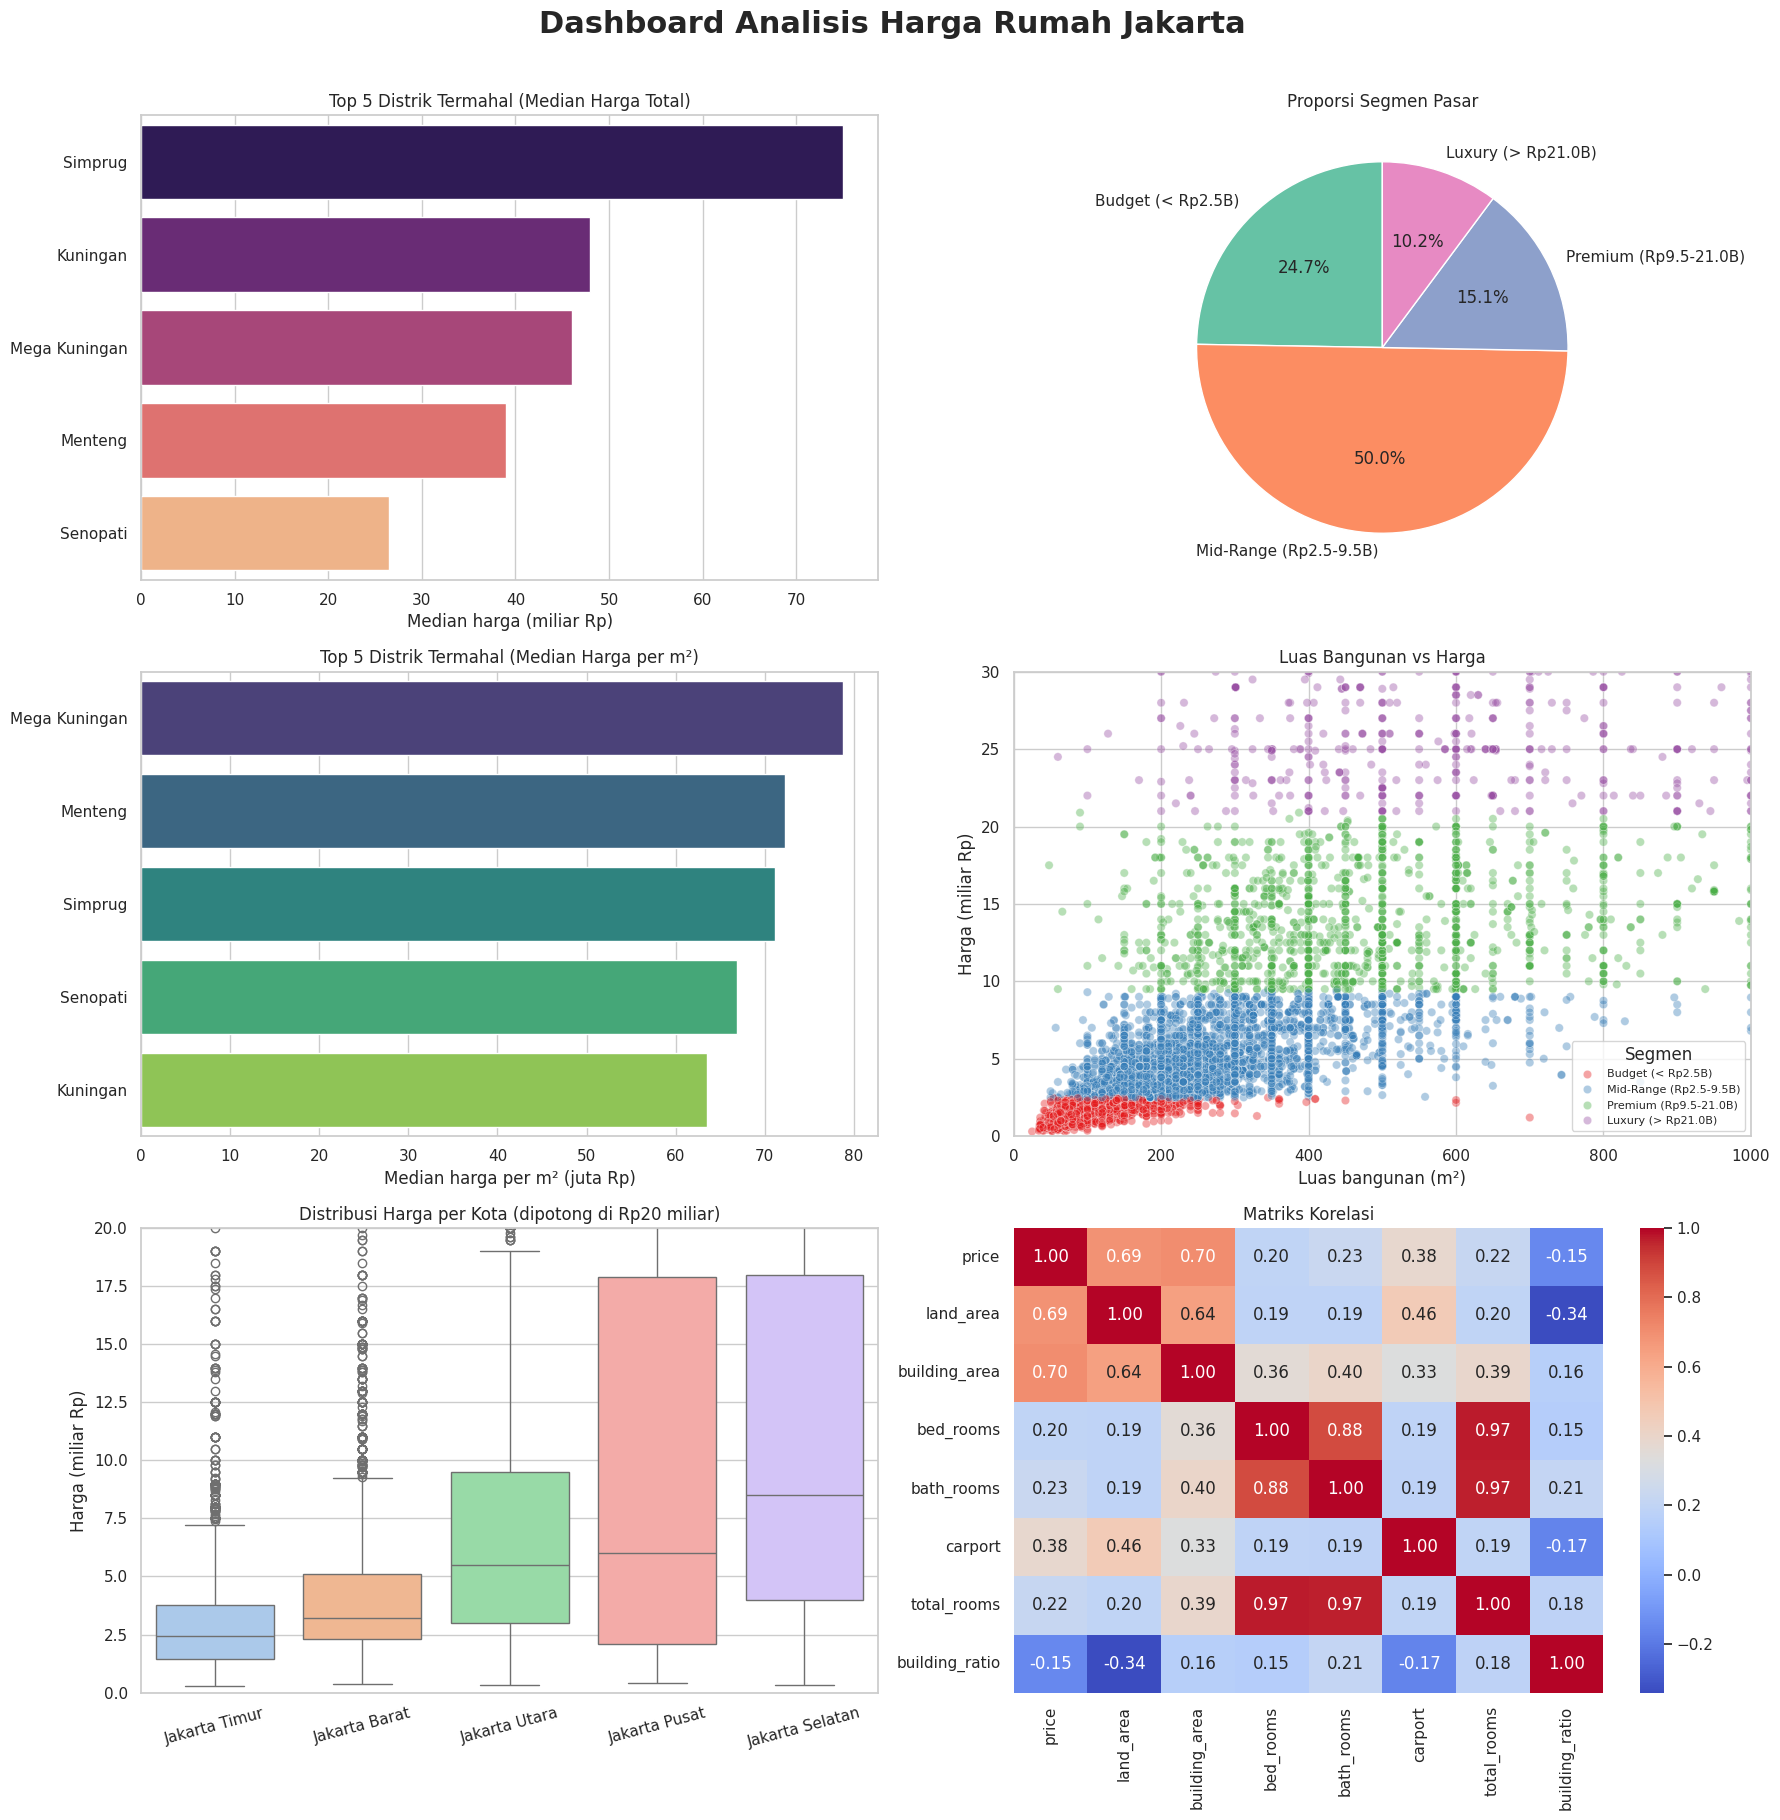

In [100]:
# Hanya distrik dengan minimal 10 rumah, supaya statistik tidak bias oleh sampel kecil
jumlah = df['district'].value_counts()
valid = jumlah[jumlah >= 10].index
df_valid = df[df['district'].isin(valid)]

fig, axes = plt.subplots(3, 2, figsize=(18, 18))
fig.suptitle('Dashboard Analisis Harga Rumah Jakarta', fontsize=22, fontweight='bold', y=1.01)

# 1. Top 5 Distrik Termahal (median harga total)
top5 = df_valid.groupby('district')['price'].median().sort_values(ascending=False).head(5) / 1e9
sns.barplot(x=top5.values, y=top5.index, hue=top5.index, palette='magma',
            legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Top 5 Distrik Termahal (Median Harga Total)')
axes[0, 0].set_xlabel('Median harga (miliar Rp)')
axes[0, 0].set_ylabel('')

# 2. Proporsi segmen pasar (urut dari murah ke mahal)
kategori_count = df['price_category'].value_counts().reindex(urutan)
axes[0, 1].pie(kategori_count.values, labels=kategori_count.index, autopct='%1.1f%%',
               colors=sns.color_palette('Set2', len(urutan)), startangle=90)
axes[0, 1].set_title('Proporsi Segmen Pasar')

# 3. Top 5 Distrik Termahal per m² (median)
top5_m2 = df_valid.groupby('district')['price_per_m2'].median().sort_values(ascending=False).head(5) / 1e6
sns.barplot(x=top5_m2.values, y=top5_m2.index, hue=top5_m2.index, palette='viridis',
            legend=False, ax=axes[1, 0])
axes[1, 0].set_title('Top 5 Distrik Termahal (Median Harga per m²)')
axes[1, 0].set_xlabel('Median harga per m² (juta Rp)')
axes[1, 0].set_ylabel('')

# 4. Scatter: Luas Bangunan vs Harga
sns.scatterplot(x=df['building_area'], y=df['price'] / 1e9, hue=df['price_category'],
                hue_order=urutan, palette='Set1', alpha=0.4, ax=axes[1, 1])
axes[1, 1].set_title('Luas Bangunan vs Harga')
axes[1, 1].set_xlabel('Luas bangunan (m²)')
axes[1, 1].set_ylabel('Harga (miliar Rp)')
axes[1, 1].set_xlim(0, 1000)
axes[1, 1].set_ylim(0, 30)
axes[1, 1].legend(title='Segmen', fontsize=8)

# 5. Boxplot: Harga per Kota (urut dari median termurah)
urut_kota = df.groupby('city')['price'].median().sort_values().index
sns.boxplot(x=df['city'], y=df['price'] / 1e9, order=urut_kota, hue=df['city'],
            hue_order=urut_kota, palette='pastel', legend=False, ax=axes[2, 0])
axes[2, 0].set_title('Distribusi Harga per Kota (dipotong di Rp20 miliar)')
axes[2, 0].set_xlabel('')
axes[2, 0].set_ylabel('Harga (miliar Rp)')
axes[2, 0].tick_params(axis='x', rotation=15)
axes[2, 0].set_ylim(0, 20)

# 6. Heatmap Korelasi
korelasi = df[['price', 'land_area', 'building_area', 'bed_rooms',
               'bath_rooms', 'carport', 'total_rooms', 'building_ratio']].corr()
sns.heatmap(korelasi, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[2, 1])
axes[2, 1].set_title('Matriks Korelasi')

plt.tight_layout()
plt.savefig('dashboard_jakarta_house.png', dpi=150, bbox_inches='tight')
plt.show()

# 6. Kesimpulan

**Temuan utama**
- Luas bangunan dan luas tanah adalah faktor yang paling berkorelasi dengan harga rumah di Jakarta (r ≈ 0,70 dan 0,69), jauh di atas jumlah kamar.
- Harga per m² sangat berbeda antar wilayah: Median harga per m² tertinggi ada di Mega Kuningan (sekitar Rp78,8 juta) dan terendah di Legenda Wisata (sekitar Rp10,7 juta), selisih sekitar 7,4 kali..
- Jakarta Timur didominasi rumah segmen budget, sedangkan Jakarta Pusat dan Selatan memiliki porsi luxury terbesar.
- Untuk pembeli rumah pertama, distrik seperti Jagakarsa, Rawamangun, dan Tebet menawarkan banyak rumah dengan harga di bawah median namun jumlah kamar di atas median.

**Rekomendasi**
- Pembeli dengan anggaran terbatas dapat memprioritaskan distrik pinggiran timur dan selatan yang memiliki harga per m² rendah.
- Gunakan luas bangunan, bukan jumlah kamar, sebagai acuan utama saat membandingkan harga.

**Keterbatasan**
- Data kemungkinan merupakan harga listing, bukan harga transaksi.
- Beberapa kategori (misalnya rumah dengan kamar sangat banyak) memiliki sampel kecil.
- Analisis ini bersifat deskriptif. Korelasi tidak membuktikan sebab-akibat, dan belum ada model prediksi.

**Langkah berikutnya:** membangun model prediksi harga dan membuat dashboard interaktif.